In [2]:
import pandas as pd

df_countries = pd.read_csv("Country-data.csv")
df_dict = pd.read_csv("data-dictionary.csv")

df_countries.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [3]:
df_countries.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [4]:
df_countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
country       167 non-null object
child_mort    167 non-null float64
exports       167 non-null float64
health        167 non-null float64
imports       167 non-null float64
income        167 non-null int64
inflation     167 non-null float64
life_expec    167 non-null float64
total_fer     167 non-null float64
gdpp          167 non-null int64
dtypes: float64(7), int64(2), object(1)
memory usage: 13.1+ KB


In [5]:
print("Number of duplicated datapoints: ",df_countries.duplicated().sum(),"\n\nNumber of missing values by column:")
df_countries.isnull().sum()

Number of duplicated datapoints:  0 

Number of missing values by column:


country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [6]:
## Create separate DataFrames for labels and features
country_names = df_countries[['country']]
country_features = df_countries.drop('country', axis =1)

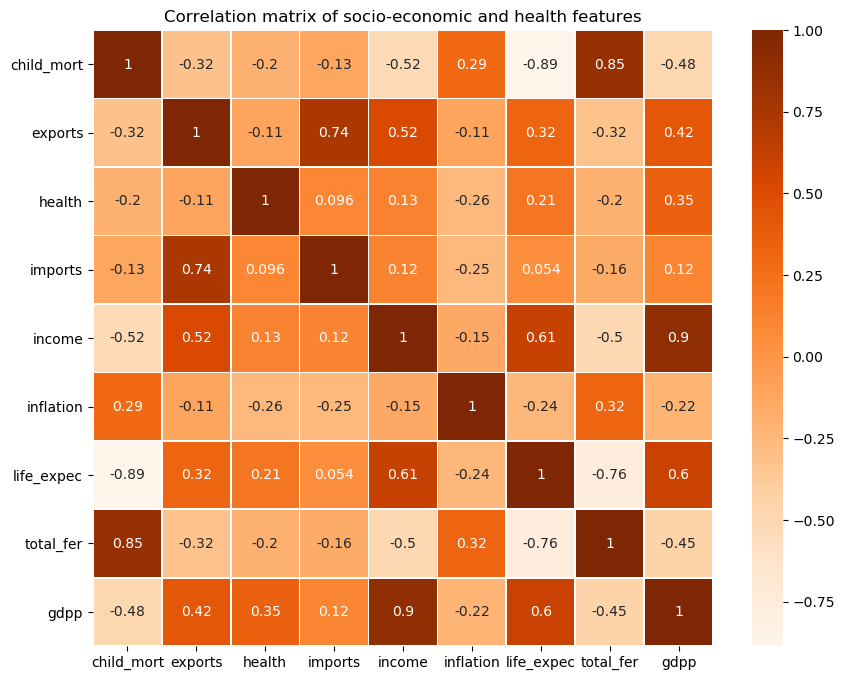

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = country_features.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,       
    cmap="Oranges",      
    linewidths=0.5,
)
plt.title("Correlation matrix of socio-economic and health features")
plt.show()

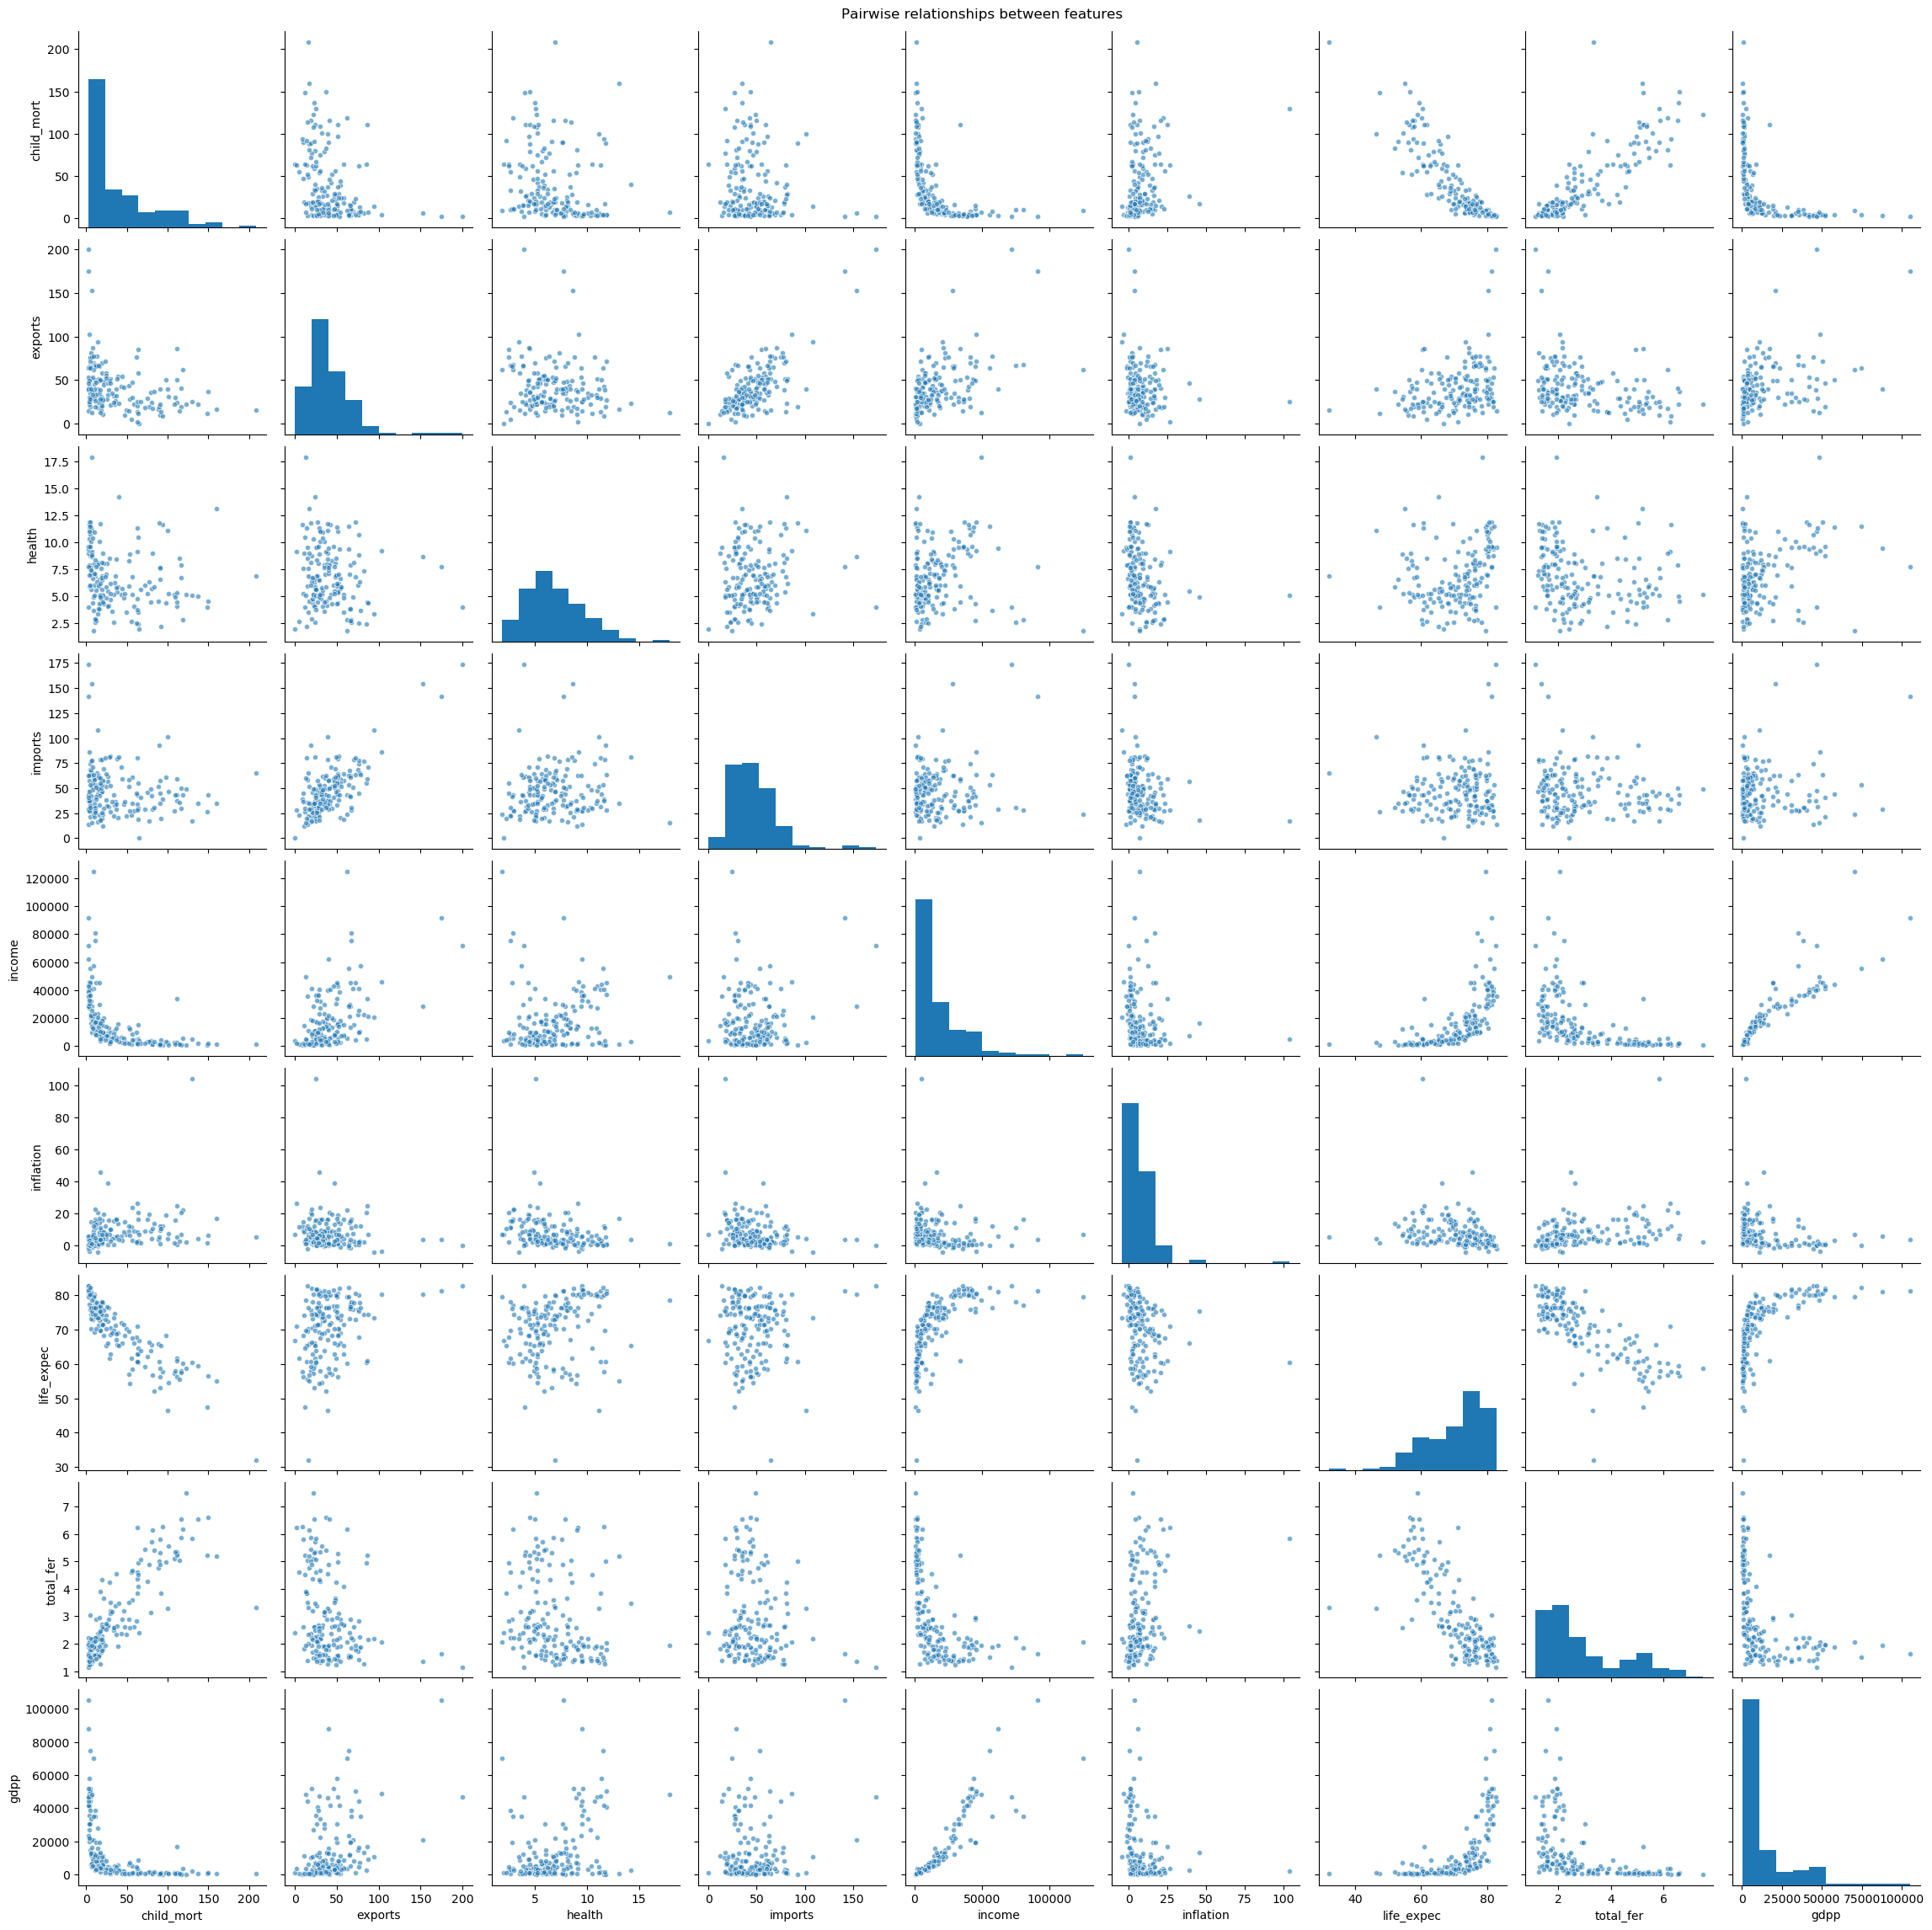

In [8]:
# Histogram and Scatterplot
sns.pairplot(country_features, diag_kind="hist", plot_kws={"alpha": 0.6, "s":20})
plt.suptitle("Pairwise relationships between features", y=1.01)
plt.show()

### Observations
Looking at the heatmap, the features aren't independent. From `income`, `gdpp` and `life_expec` all go up together and all go down as `child_mort` and `total_fer`go up. The strongest pairs are `child_mort` and `life_expec` at -0.89, `income` and `gdpp` at +0.90, and `child_mort` and `total_fer` at +0.85. Basically, if Iknow a country's child mortality I can already guess most of its other numbers.`exports` and `imports` correlate with each other (+0.74) but not with much else,so trade seems to be its own separate thing, and `health` and `inflation` are the weakest overall (`health` only gets to +0.35 with `gdpp`). 

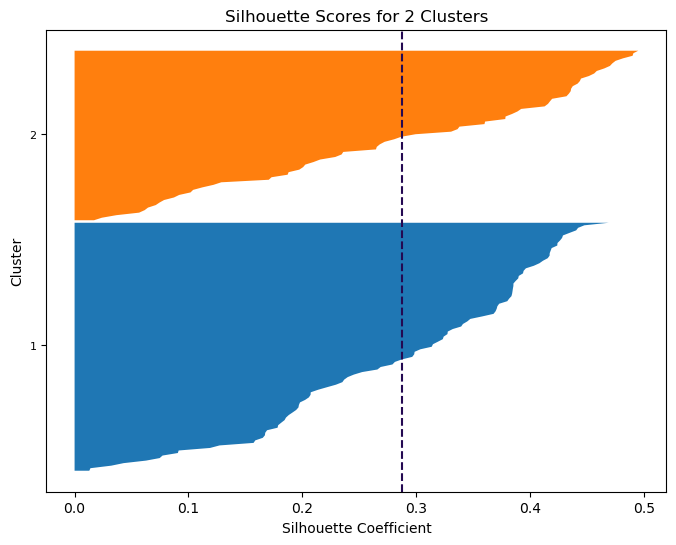

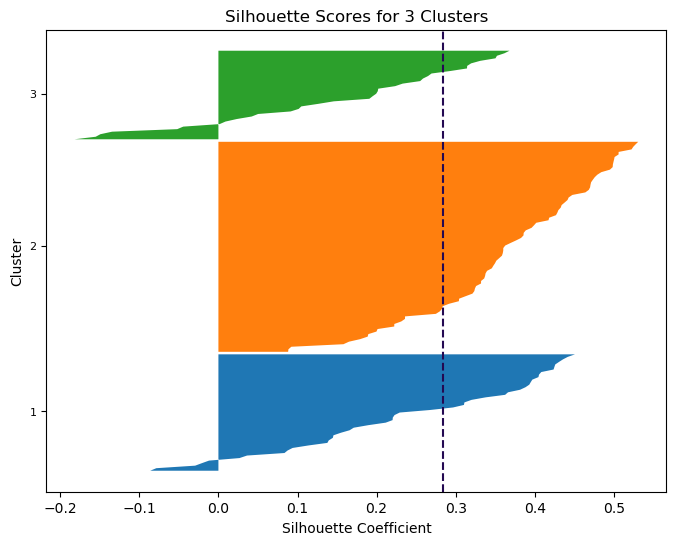

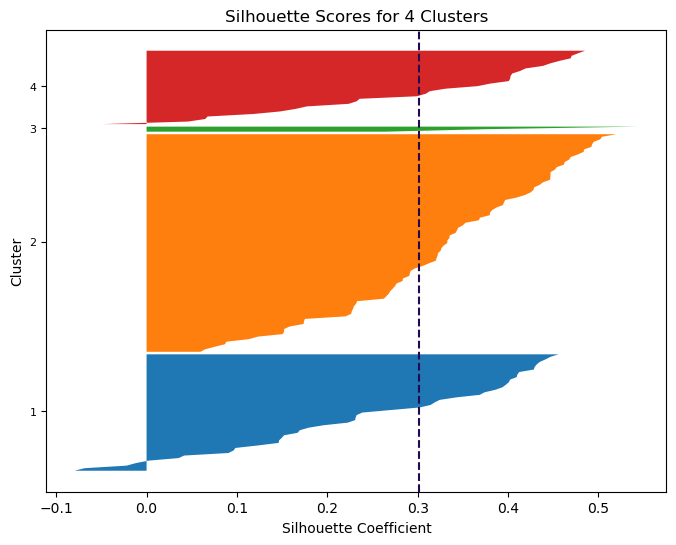

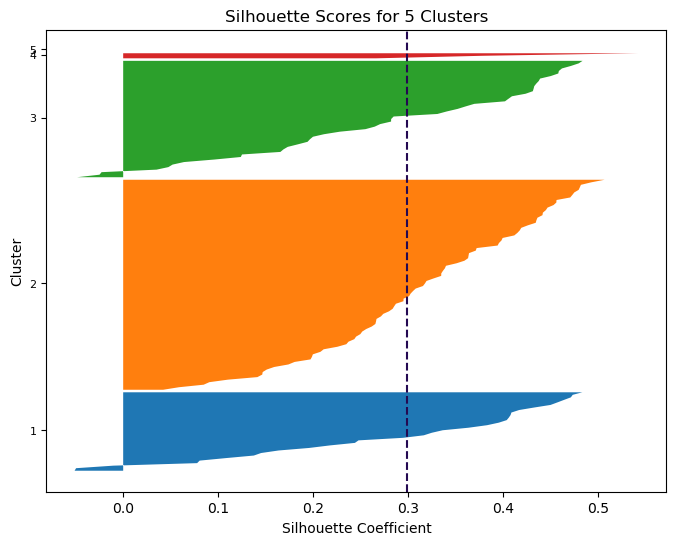

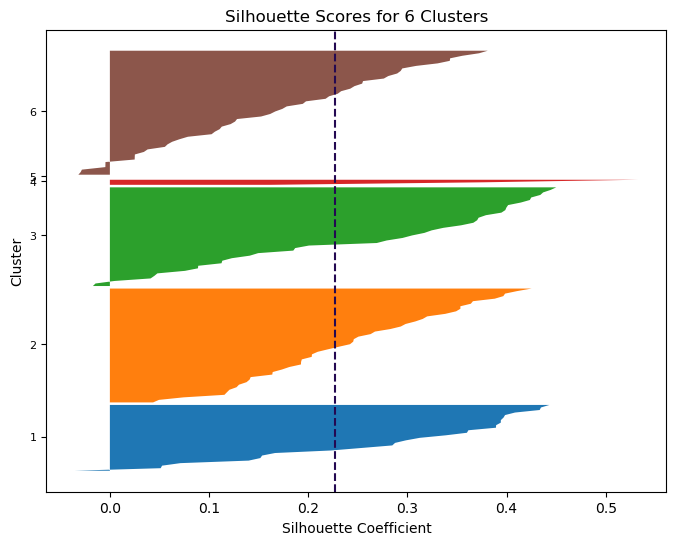

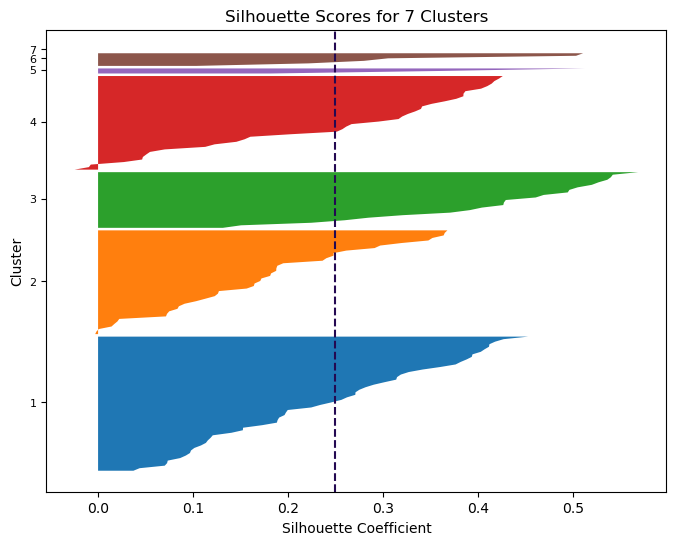

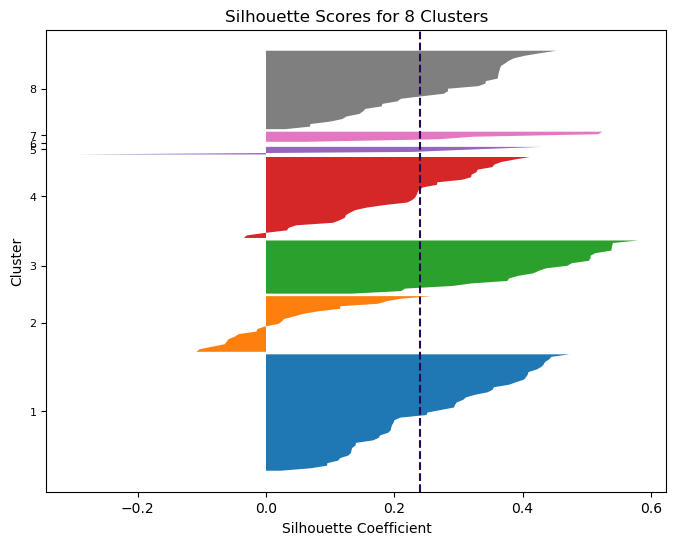

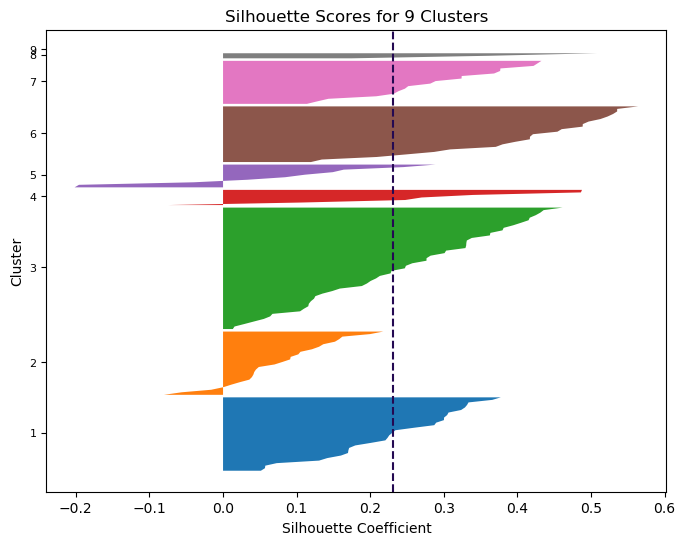

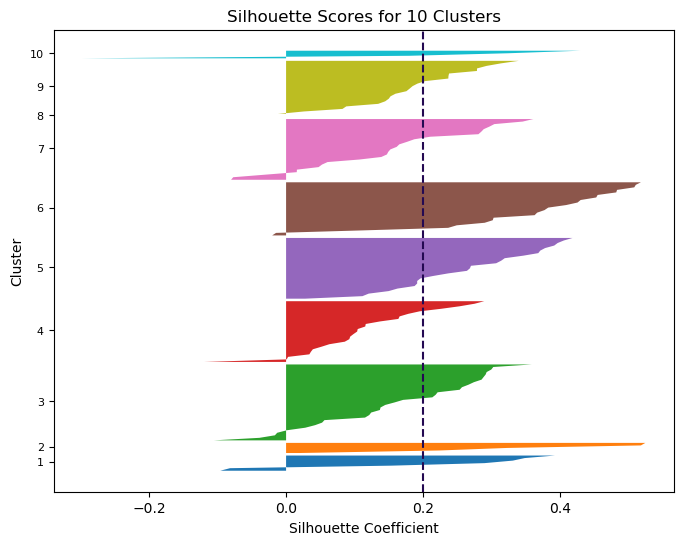

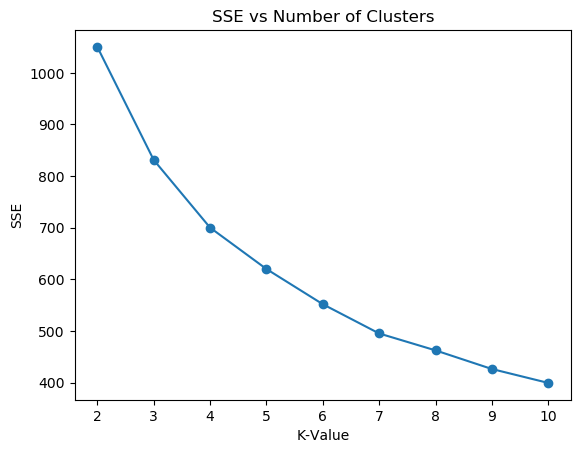

In [ ]:
from sklearn.preprocessing import StandardScaler as scaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score as s_score, silhouette_samples as s_samples
import numpy as np

def check_range(k_bounds):
    # Compare parameter types, change return based on input
    if type(k_bounds) == int or type(k_bounds) == float:
        if k_bounds < 2:
            k_bounds = [2]
        else:
            k_bounds = [round(k_bounds)]
    elif type(k_bounds) == tuple:
        k_bounds = list(k_bounds)
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    elif type(k_bounds) == list:
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    return k_bounds

def get_kmeans(x_var, y_var=None, k_range=2, lamda=0.0001, epoch=500):

    # Determine number of clusters. if unspecified default to 2
    num_clusters = check_range(k_range)

    # Initiallize containers for metrics of different k values
    kmeans_metrics = {
    }
    kmeans_sse = []

    # Run K-Means for k number of clusters
    for k in range(num_clusters[0],num_clusters[-1]+1):
        train_data = scaler().fit_transform(x_var)
        test_model = KMeans(k, random_state=42, max_iter=epoch, tol=lamda).fit(train_data)

        # Add metrics to history
        centroids = test_model.cluster_centers_
        labels = test_model.labels_
        SSE = test_model.inertia_
        silhouette_avg = s_score(train_data,labels)
        silhouette_values = s_samples(train_data, labels)

    # Store model metrics in dictionary
        metrics = {
            "Silhouette Score": silhouette_avg,
            "Silhouette Samples": silhouette_values,
            "SSE": SSE,
            "Centroids": centroids,
            "Labels": labels,
        }

        kmeans_metrics[f"{k} Clusters"] = metrics

    # Plot Silhouette vs Cluster
        prev_cluster_size = 0
        silhouette_plot, axis = plt.subplots(figsize=(8,6))
        for i in range(0,k):
            tick_loc = []
            for n in range(k):
                nth_cluster_values = silhouette_values[labels==n]
                nth_cluster_values.sort()
                nth_cluster_size = len(nth_cluster_values)
                tick_loc.append(nth_cluster_size/2+prev_cluster_size)
                y_upper_bounds = prev_cluster_size + nth_cluster_size
                axis.fill_betweenx(np.arange(prev_cluster_size,y_upper_bounds),0,nth_cluster_values)
                prev_cluster_size += nth_cluster_size
            axis.set_yticks(tick_loc)
            axis.set_yticklabels(np.arange(1,n+2), fontsize=8)
            axis.axvline(silhouette_avg,c=(36/255.0, 9/255.0, 82/255.0),linestyle="--")
            axis .set_title(f"Silhouette Scores for {k} Clusters")
            axis.set_ylabel("Cluster")
            axis.set_xlabel("Silhouette Coefficient")
            plt.show()

        kmeans_sse.append(SSE)
    # Plots Elbow Graph for K-Means
    plt.plot(range(num_clusters[0],num_clusters[-1]+1),kmeans_sse,'o-',)
    plt.title("SSE vs Number of Clusters")
    plt.xlabel("K-Value")
    plt.ylabel("SSE")
    plt.show()

    return kmeans_metrics

# Runs get_kmeans() and stores values in variable
kmeans_metrics = get_kmeans(country_features,k_range=(2,10))

In [27]:
chosen_model = kmeans_metrics["4 Clusters"]
chosen_model

{'Silhouette Score': 0.301375962376881,
 'Silhouette Samples': array([ 0.42935825,  0.48404864,  0.40972131,  0.32433882,  0.39537074,
         0.26806233,  0.49218237,  0.41333988,  0.47033036,  0.37999466,
         0.05960355,  0.11317875,  0.26968586,  0.29711288,  0.446874  ,
         0.31342883,  0.47710582,  0.36871492,  0.4248905 ,  0.31995437,
         0.23190199, -0.07965347,  0.23283441,  0.14777841,  0.43863177,
         0.45589017,  0.34284345,  0.30613655,  0.40088124,  0.46921102,
         0.43506339,  0.38601183,  0.42851955,  0.26528558,  0.45173412,
         0.34473111,  0.23877352,  0.40952626,  0.098287  ,  0.17515036,
         0.39757968,  0.26264536,  0.04573167,  0.06494549,  0.47745304,
         0.45394973,  0.42812429,  0.32244152,  0.50388161,  0.1461373 ,
         0.16714638,  0.27496625,  0.38226353,  0.44667842,  0.41928764,
         0.03552167,  0.31872707,  0.38687825,  0.45693702,  0.23127073,
         0.23573751,  0.48352898,  0.3353536 ,  0.43159346,  0